데이터 분할 완료: Train 331,219개 / Test 82,805개

선형 회귀 (Linear Regression)   | R²: 0.0639 | RMSE: 809.02건 | MAE: 435.83건
랜덤 포레스트 (Random Forest) -> | R²: 0.0641 | RMSE: 808.91건 | MAE: 435.70건


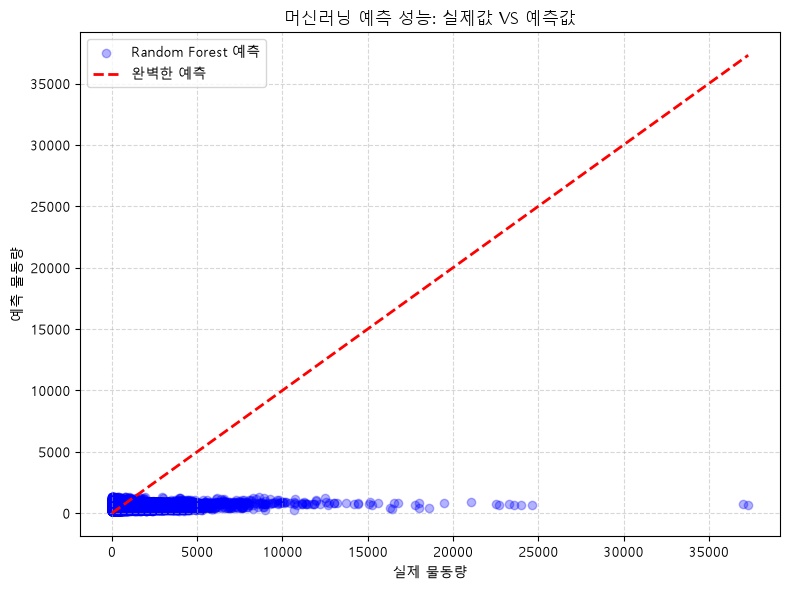

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 글자 깨짐 방지
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 전처리 불러오기
data = pd.read_csv('preprocessed_parcel_data.csv', encoding='utf-8', dtype={'우편번호 5자리': str},)

# 범주형 변수 (시,도) One-Hot Encoding
df_ml = pd.get_dummies(data, columns=['시''도'], drop_first=True)

# 독립변수(X)와 종속변수(y) 분리
X = df_ml.drop(columns=['우편번호 5자리','월','물동량'])
Y = df_ml['물동량']

# Train 데이터 / Test 데이터 분리 (8:2)
X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

print(f'데이터 분할 완료: Train {X_train.shape[0]:,}개 / Test {X_test.shape[0]:,}개')

# 선형회귀
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# r2 = 결정계수, rmse = 평균 제곱 오차, mae = 평균 절대 오차
lr_r2 = r2_score(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_mae = mean_absolute_error(y_test, y_pred_lr)

# 랜덤포레스트 회귀
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test,y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print('\n==================================================')
print(f'선형 회귀 (Linear Regression)   | R²: {lr_r2:.4f} | RMSE: {lr_rmse:.2f}건 | MAE: {lr_mae:.2f}건')
print(f'랜덤 포레스트 (Random Forest) -> | R²: {rf_r2:.4f} | RMSE: {rf_rmse:.2f}건 | MAE: {rf_mae:.2f}건')
print('==================================================')

# 실제 값, 예측 값 시각화
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_rf, alpha = 0.3, color='blue', label = 'Random Forest 예측')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='완벽한 예측')
plt.xlabel('실제 물동량')
plt.ylabel('예측 물동량')
plt.title('머신러닝 예측 성능: 실제값 VS 예측값')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()